In [2]:
# Cell 1 — load data and make ONE fixed split
from google.colab import drive
drive.mount('/content/drive')
!unzip -q -o "/content/drive/MyDrive/wound_images.zip" -d /content/data
!ls /content/data

Mounted at /content/drive
wound_images


In [3]:
import os
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices('GPU'))

DATA_DIR = "/content/data/wound_images"
print(os.listdir(DATA_DIR))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
['Background', 'Pressure', 'Surgical', 'Normal', 'Venous', 'Diabetic']


In [4]:
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
class_names = sorted(os.listdir(DATA_DIR))

paths, labels = [], []
for idx, cls in enumerate(class_names):
    folder = os.path.join(DATA_DIR, cls)
    for f in os.listdir(folder):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(folder, f))
            labels.append(idx)

paths, labels = np.array(paths), np.array(labels)

train_p, temp_p, train_y, temp_y = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)

print("Classes:", class_names)
print("Total:", len(paths))
for name, y in [("Train", train_y), ("Val", val_y), ("Test", test_y)]:
    print(f"{name}: {len(y)} images, per class: {np.bincount(y)}")

Classes: ['Background', 'Diabetic', 'Normal', 'Pressure', 'Surgical', 'Venous']
Total: 738
Train: 516 images, per class: [ 70 108  70  70  89 109]
Val: 111 images, per class: [15 23 15 15 19 24]
Test: 111 images, per class: [15 23 15 15 20 23]


Batch shape: (32, 224, 224, 3) | pixel range: 0.0 to 255.0


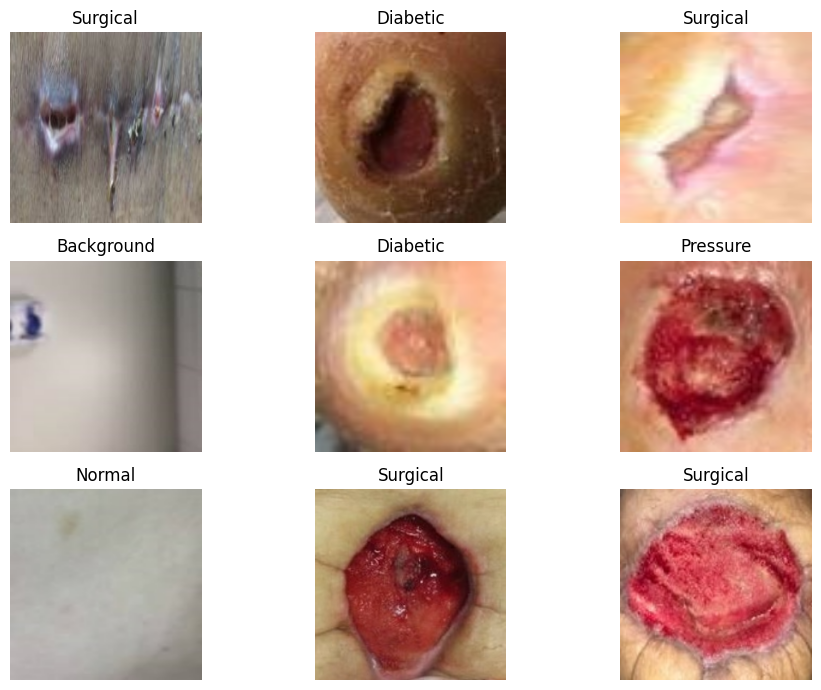

In [5]:
IMG_SIZE = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_p, train_y, training=True)
val_ds   = make_ds(val_p, val_y)
test_ds  = make_ds(test_p, test_y)

import matplotlib.pyplot as plt
imgs, lbls = next(iter(train_ds))
print("Batch shape:", imgs.shape, "| pixel range:", float(tf.reduce_min(imgs)), "to", float(tf.reduce_max(imgs)))

plt.figure(figsize=(10, 7))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(imgs[i].numpy().astype("uint8"))
    plt.title(class_names[lbls[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
import time
import pandas as pd
from tensorflow.keras import layers
from sklearn.metrics import f1_score

SAVE_DIR = "/content/drive/MyDrive/WoundNet/models"
os.makedirs(SAVE_DIR, exist_ok=True)
NUM_CLASSES = len(class_names)
EPOCHS = 30

def make_augment():
    return tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ])

results, histories = [], {}

def run_experiment(name, build_fn, epochs=EPOCHS, lr=1e-3):
    tf.keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

    start = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=2)
    train_time = time.time() - start

    t0 = time.time()
    y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
    ms_per_img = (time.time() - t0) / len(test_y) * 1000

    va = h.history["val_accuracy"]
    results.append({
        "model": name,
        "params": model.count_params(),
        "val_acc_ep10": round(va[min(10, len(va)) - 1], 3),
        "val_acc_ep20": round(va[min(20, len(va)) - 1], 3),
        "val_acc_ep30": round(va[min(30, len(va)) - 1], 3),
        "test_acc": round(float((y_pred == test_y).mean()), 3),
        "macro_f1": round(f1_score(test_y, y_pred, average="macro"), 3),
        "train_time_s": round(train_time, 1),
        "ms_per_image": round(ms_per_img, 2),
    })
    histories[name] = h.history
    model.save(f"{SAVE_DIR}/{name}.keras")
    pd.DataFrame(results).to_csv(f"{SAVE_DIR}/results.csv", index=False)
    print(f"\n{name}: test_acc={results[-1]['test_acc']}  macro_f1={results[-1]['macro_f1']}\n")
    return model

In [7]:
def build_mlp(hidden):
    def build():
        inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
        x = make_augment()(inputs)
        x = layers.Resizing(64, 64)(x)
        x = layers.Rescaling(1./255)(x)
        x = layers.Flatten()(x)
        for units in hidden:
            x = layers.Dense(units, activation="relu")(x)
            x = layers.Dropout(0.3)(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
        return tf.keras.Model(inputs, outputs)
    return build

for hidden in [(512,), (512, 256), (512, 256, 128)]:
    run_experiment(f"MLP_{len(hidden)}hidden", build_mlp(hidden))

pd.DataFrame(results)

Epoch 1/30
17/17 - 5s - 276ms/step - accuracy: 0.2035 - loss: 14.5202 - val_accuracy: 0.1712 - val_loss: 5.9413
Epoch 2/30
17/17 - 2s - 110ms/step - accuracy: 0.2403 - loss: 4.6236 - val_accuracy: 0.2613 - val_loss: 1.8855
Epoch 3/30
17/17 - 0s - 21ms/step - accuracy: 0.2771 - loss: 1.9906 - val_accuracy: 0.3964 - val_loss: 1.6615
Epoch 4/30
17/17 - 0s - 21ms/step - accuracy: 0.3140 - loss: 1.7193 - val_accuracy: 0.3694 - val_loss: 1.6342
Epoch 5/30
17/17 - 0s - 20ms/step - accuracy: 0.3062 - loss: 1.6856 - val_accuracy: 0.4324 - val_loss: 1.5744
Epoch 6/30
17/17 - 1s - 38ms/step - accuracy: 0.3275 - loss: 1.6379 - val_accuracy: 0.2703 - val_loss: 1.5775
Epoch 7/30
17/17 - 0s - 21ms/step - accuracy: 0.3333 - loss: 1.6169 - val_accuracy: 0.4054 - val_loss: 1.5513
Epoch 8/30
17/17 - 1s - 36ms/step - accuracy: 0.3353 - loss: 1.5925 - val_accuracy: 0.3784 - val_loss: 1.5763
Epoch 9/30
17/17 - 1s - 36ms/step - accuracy: 0.3198 - loss: 1.6089 - val_accuracy: 0.4505 - val_loss: 1.5313
Epoch 1


MLP_3hidden: test_acc=0.207  macro_f1=0.057



,model,params,val_acc_ep10,val_acc_ep20,val_acc_ep30,test_acc,macro_f1,train_time_s,ms_per_image
0,MLP_1hidden,6295046,0.360,0.387,0.378,0.378,0.288,19.1,1.95
1,MLP_2hidden,6424838,0.315,0.333,0.324,0.306,0.199,14.5,1.47
2,MLP_3hidden,6456966,0.306,0.243,0.216,0.207,0.057,15.9,1.63


In [8]:
results = [r for r in results if not r["model"].startswith("CNN")]

def build_cnn(n_blocks):
    def build():
        inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
        x = make_augment()(inputs)
        x = layers.Rescaling(1./255)(x)
        filters = 32
        for _ in range(n_blocks):
            x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
            x = layers.BatchNormalization(momentum=0.9)(x)
            x = layers.MaxPooling2D()(x)
            filters *= 2
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(128, activation="relu")(x)
        x = layers.Dropout(0.3)(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
        return tf.keras.Model(inputs, outputs)
    return build

for n in [2, 3, 4]:
    run_experiment(f"CNN_{n}blocks", build_cnn(n))

pd.DataFrame(results)

Epoch 1/30
17/17 - 7s - 401ms/step - accuracy: 0.3295 - loss: 1.6364 - val_accuracy: 0.2703 - val_loss: 1.7360
Epoch 2/30
17/17 - 2s - 97ms/step - accuracy: 0.4787 - loss: 1.3624 - val_accuracy: 0.3694 - val_loss: 1.5940
Epoch 3/30
17/17 - 2s - 97ms/step - accuracy: 0.4864 - loss: 1.3249 - val_accuracy: 0.4595 - val_loss: 1.3702
Epoch 4/30
17/17 - 2s - 103ms/step - accuracy: 0.4981 - loss: 1.3153 - val_accuracy: 0.5135 - val_loss: 1.2228
Epoch 5/30
17/17 - 2s - 105ms/step - accuracy: 0.5271 - loss: 1.2396 - val_accuracy: 0.4955 - val_loss: 1.3133
Epoch 6/30
17/17 - 2s - 143ms/step - accuracy: 0.5620 - loss: 1.1926 - val_accuracy: 0.3423 - val_loss: 1.9559
Epoch 7/30
17/17 - 2s - 98ms/step - accuracy: 0.5213 - loss: 1.1934 - val_accuracy: 0.4865 - val_loss: 1.2155
Epoch 8/30
17/17 - 2s - 98ms/step - accuracy: 0.5271 - loss: 1.1771 - val_accuracy: 0.5586 - val_loss: 1.1249
Epoch 9/30
17/17 - 3s - 150ms/step - accuracy: 0.5310 - loss: 1.1843 - val_accuracy: 0.4144 - val_loss: 1.4403
Epoch

,model,params,val_acc_ep10,val_acc_ep20,val_acc_ep30,test_acc,macro_f1,train_time_s,ms_per_image
0,MLP_1hidden,6295046,0.360,0.387,0.378,0.378,0.288,19.1,1.95
1,MLP_2hidden,6424838,0.315,0.333,0.324,0.306,0.199,14.5,1.47
2,MLP_3hidden,6456966,0.306,0.243,0.216,0.207,0.057,15.9,1.63
3,CNN_2blocks,28870,0.468,0.604,0.640,0.514,0.493,58.8,2.40
4,CNN_3blocks,111430,0.468,0.622,0.613,0.577,0.579,65.7,2.97
5,CNN_4blocks,424006,0.577,0.550,0.550,0.541,0.535,71.4,3.62


In [9]:
from tensorflow.keras.applications import MobileNetV2

def build_mobilenet(hidden):
    def build():
        base = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
        base.trainable = False
        inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
        x = make_augment()(inputs)
        x = layers.Rescaling(1./127.5, offset=-1)(x)
        x = base(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.3)(x)
        for units in hidden:
            x = layers.Dense(units, activation="relu")(x)
            x = layers.Dropout(0.3)(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
        return tf.keras.Model(inputs, outputs)
    return build

for hidden in [(), (128,), (256, 128)]:
    run_experiment(f"MobileNetV2_{len(hidden)}hidden", build_mobilenet(hidden))

pd.DataFrame(results)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/30
17/17 - 7s - 432ms/step - accuracy: 0.3004 - loss: 2.0237 - val_accuracy: 0.6306 - val_loss: 1.1143
Epoch 2/30
17/17 - 1s - 69ms/step - accuracy: 0.5581 - loss: 1.2218 - val_accuracy: 0.7387 - val_loss: 0.8220
Epoch 3/30
17/17 - 1s - 69ms/step - accuracy: 0.6473 - loss: 1.0104 - val_accuracy: 0.7207 - val_loss: 0.7253
Epoch 4/30
17/17 - 1s - 69ms/step - accuracy: 0.6550 - loss: 0.8804 - val_accuracy: 0.7297 - val_loss: 0.6498
Epoch 5/30
17/17 - 1s - 69ms/step - accuracy: 0.6938 - loss: 0.8116 - val_accuracy: 0.7568 - val_loss: 0.6028
Epoch 6/30
17/17 - 1s - 70ms/step - accuracy: 0.7306 - loss: 0.7426 - val_accuracy: 0.7748 - val_loss: 0.5876
Epoch 7/30
17/17 - 1s - 68ms/step - accuracy: 0.7733 - loss: 0.6967 - val_accuracy: 0.7477 - val_loss: 0.5705
Epoch 8/30
17/17 - 1s - 69ms/step - accuracy: 0.7519 - loss: 0.6653 - val_accuracy: 0.7658 - val_loss: 0.5553
Epoch 9/30
17/17 - 1s - 71ms/step - accuracy: 0.7403 - loss: 0.6748 - 

,model,params,val_acc_ep10,val_acc_ep20,val_acc_ep30,test_acc,macro_f1,train_time_s,ms_per_image
0,MLP_1hidden,6295046,0.360,0.387,0.378,0.378,0.288,19.1,1.95
1,MLP_2hidden,6424838,0.315,0.333,0.324,0.306,0.199,14.5,1.47
2,MLP_3hidden,6456966,0.306,0.243,0.216,0.207,0.057,15.9,1.63
3,CNN_2blocks,28870,0.468,0.604,0.640,0.514,0.493,58.8,2.40
4,CNN_3blocks,111430,0.468,0.622,0.613,0.577,0.579,65.7,2.97
5,CNN_4blocks,424006,0.577,0.550,0.550,0.541,0.535,71.4,3.62
6,MobileNetV2_0hidden,2265670,0.784,0.802,0.793,0.703,0.694,42.4,19.81
7,MobileNetV2_1hidden,2422726,0.775,0.802,0.775,0.703,0.708,42.3,20.36
8,MobileNetV2_2hidden,2619590,0.784,0.802,0.784,0.748,0.752,42.7,19.80


In [10]:
tf.keras.utils.set_random_seed(SEED)
model = tf.keras.models.load_model(f"{SAVE_DIR}/MobileNetV2_0hidden.keras")
base = next(l for l in model.layers if l.name.startswith("mobilenetv2"))

base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                         restore_best_weights=True)
start = time.time()
h = model.fit(train_ds, validation_data=val_ds, epochs=30,
              callbacks=[early], verbose=2)
train_time = time.time() - start

t0 = time.time()
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
ms_per_img = (time.time() - t0) / len(test_y) * 1000

name = "MobileNetV2_finetuned"
va = h.history["val_accuracy"]
results.append({
    "model": name,
    "params": model.count_params(),
    "val_acc_ep10": round(va[min(10, len(va)) - 1], 3),
    "val_acc_ep20": round(va[min(20, len(va)) - 1], 3),
    "val_acc_ep30": round(va[min(30, len(va)) - 1], 3),
    "test_acc": round(float((y_pred == test_y).mean()), 3),
    "macro_f1": round(f1_score(test_y, y_pred, average="macro"), 3),
    "train_time_s": round(train_time, 1),
    "ms_per_image": round(ms_per_img, 2),
})
histories[name] = h.history
model.save(f"{SAVE_DIR}/{name}.keras")
pd.DataFrame(results).to_csv(f"{SAVE_DIR}/results.csv", index=False)
print(f"\n{name}: stopped after {len(va)} epochs")
pd.DataFrame(results)

Epoch 1/30
17/17 - 10s - 569ms/step - accuracy: 0.8508 - loss: 0.3947 - val_accuracy: 0.8108 - val_loss: 0.4974
Epoch 2/30
17/17 - 1s - 76ms/step - accuracy: 0.8547 - loss: 0.3849 - val_accuracy: 0.8018 - val_loss: 0.5094
Epoch 3/30
17/17 - 1s - 75ms/step - accuracy: 0.8430 - loss: 0.3984 - val_accuracy: 0.8108 - val_loss: 0.5222
Epoch 4/30
17/17 - 1s - 78ms/step - accuracy: 0.8585 - loss: 0.3769 - val_accuracy: 0.8018 - val_loss: 0.5018
Epoch 5/30
17/17 - 1s - 77ms/step - accuracy: 0.8779 - loss: 0.3568 - val_accuracy: 0.8108 - val_loss: 0.5285
Epoch 6/30
17/17 - 1s - 77ms/step - accuracy: 0.8643 - loss: 0.3518 - val_accuracy: 0.7928 - val_loss: 0.5088

MobileNetV2_finetuned: stopped after 6 epochs


,model,params,val_acc_ep10,val_acc_ep20,val_acc_ep30,test_acc,macro_f1,train_time_s,ms_per_image
0,MLP_1hidden,6295046,0.360,0.387,0.378,0.378,0.288,19.1,1.95
1,MLP_2hidden,6424838,0.315,0.333,0.324,0.306,0.199,14.5,1.47
2,MLP_3hidden,6456966,0.306,0.243,0.216,0.207,0.057,15.9,1.63
3,CNN_2blocks,28870,0.468,0.604,0.640,0.514,0.493,58.8,2.40
4,CNN_3blocks,111430,0.468,0.622,0.613,0.577,0.579,65.7,2.97
5,CNN_4blocks,424006,0.577,0.550,0.550,0.541,0.535,71.4,3.62
6,MobileNetV2_0hidden,2265670,0.784,0.802,0.793,0.703,0.694,42.4,19.81
7,MobileNetV2_1hidden,2422726,0.775,0.802,0.775,0.703,0.708,42.3,20.36
8,MobileNetV2_2hidden,2619590,0.784,0.802,0.784,0.748,0.752,42.7,19.80
9,MobileNetV2_finetuned,2265670,0.793,0.793,0.793,0.748,0.748,16.4,20.03


In [11]:
from tensorflow.keras.applications import EfficientNetB0

def build_efficientnet(hidden):
    def build():
        base = EfficientNetB0(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
        base.trainable = False
        inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
        x = make_augment()(inputs)
        x = base(x, training=False)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.3)(x)
        for units in hidden:
            x = layers.Dense(units, activation="relu")(x)
            x = layers.Dropout(0.3)(x)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
        return tf.keras.Model(inputs, outputs)
    return build

for hidden in [(), (128,)]:
    run_experiment(f"EfficientNetB0_{len(hidden)}hidden", build_efficientnet(hidden))

pd.DataFrame(results)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/30
17/17 - 15s - 874ms/step - accuracy: 0.3953 - loss: 1.5437 - val_accuracy: 0.5766 - val_loss: 1.1534
Epoch 2/30
17/17 - 2s - 93ms/step - accuracy: 0.6027 - loss: 1.0631 - val_accuracy: 0.7207 - val_loss: 0.8699
Epoch 3/30
17/17 - 2s - 92ms/step - accuracy: 0.6996 - loss: 0.8812 - val_accuracy: 0.7658 - val_loss: 0.7512
Epoch 4/30
17/17 - 2s - 93ms/step - accuracy: 0.7287 - loss: 0.7739 - val_accuracy: 0.7568 - val_loss: 0.6955
Epoch 5/30
17/17 - 2s - 92ms/step - accuracy: 0.7481 - loss: 0.7213 - val_accuracy: 0.7838 - val_loss: 0.6513
Epoch 6/30
17/17 - 2s - 94ms/step - accuracy: 0.7752 - loss: 0.6685 - val_accuracy: 0.7658 - val_loss: 0.6279
Epoch 7/30
17/17 - 2s - 93ms/step - accuracy: 0.7810 - loss: 0.6482 - val_accuracy: 0.7748 - val_loss: 0.6046
Epoch 8/30
17/17 - 2s - 93ms/step - accuracy: 0.7849 - loss: 0.6283 - val_accuracy: 0.7658 - val_loss: 0.5813
Epoch 9/30
17/17 - 2s - 94ms/step - accuracy: 0.8081 - loss: 0.5931

,model,params,val_acc_ep10,val_acc_ep20,val_acc_ep30,test_acc,macro_f1,train_time_s,ms_per_image
0,MLP_1hidden,6295046,0.360,0.387,0.378,0.378,0.288,19.1,1.95
1,MLP_2hidden,6424838,0.315,0.333,0.324,0.306,0.199,14.5,1.47
2,MLP_3hidden,6456966,0.306,0.243,0.216,0.207,0.057,15.9,1.63
3,CNN_2blocks,28870,0.468,0.604,0.640,0.514,0.493,58.8,2.40
4,CNN_3blocks,111430,0.468,0.622,0.613,0.577,0.579,65.7,2.97
5,CNN_4blocks,424006,0.577,0.550,0.550,0.541,0.535,71.4,3.62
6,MobileNetV2_0hidden,2265670,0.784,0.802,0.793,0.703,0.694,42.4,19.81
7,MobileNetV2_1hidden,2422726,0.775,0.802,0.775,0.703,0.708,42.3,20.36
8,MobileNetV2_2hidden,2619590,0.784,0.802,0.784,0.748,0.752,42.7,19.80
9,MobileNetV2_finetuned,2265670,0.793,0.793,0.793,0.748,0.748,16.4,20.03


In [12]:
best_name = "EfficientNetB0_0hidden"
best = tf.keras.models.load_model(f"{SAVE_DIR}/{best_name}.keras")

views = [
    lambda x: x,
    lambda x: tf.image.flip_left_right(x),
    lambda x: tf.image.flip_up_down(x),
    lambda x: tf.image.rot90(x),
]

def predict_tta(ds):
    probs = [best.predict(ds.map(lambda x, y: (v(x), y)), verbose=0) for v in views]
    return np.mean(probs, axis=0).argmax(axis=1)

def plain_predict(ds):
    return best.predict(ds, verbose=0).argmax(axis=1)

for split, ds, y in [("Val", val_ds, val_y), ("Test", test_ds, test_y)]:
    p_plain, p_tta = plain_predict(ds), predict_tta(ds)
    print(f"{split}:  plain acc={np.mean(p_plain == y):.3f}  F1={f1_score(y, p_plain, average='macro'):.3f}"
          f"   |   TTA acc={np.mean(p_tta == y):.3f}  F1={f1_score(y, p_tta, average='macro'):.3f}")

Val:  plain acc=0.802  F1=0.799   |   TTA acc=0.793  F1=0.794
Test:  plain acc=0.802  F1=0.800   |   TTA acc=0.811  F1=0.815


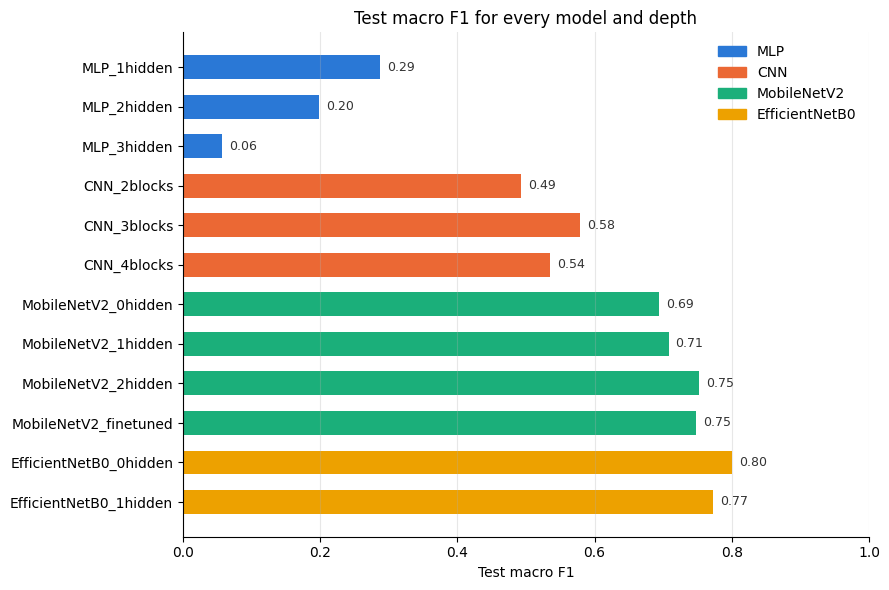

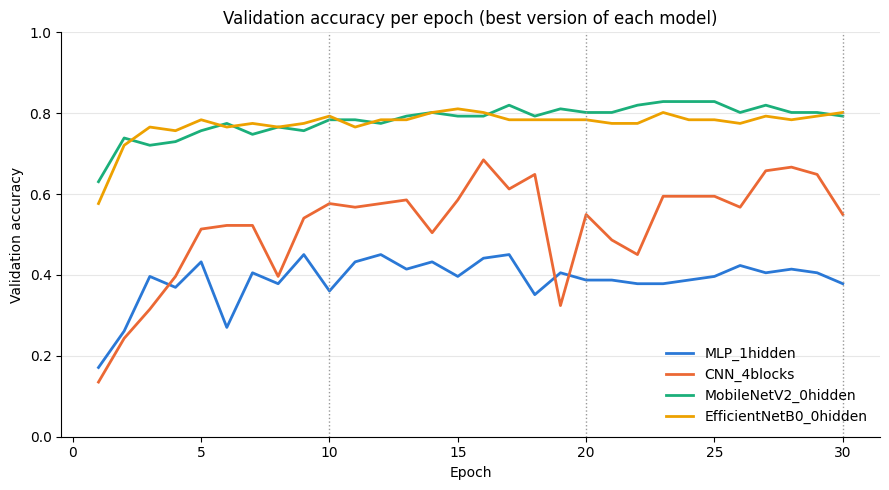

              precision    recall  f1-score   support

  Background      1.000     0.867     0.929        15
    Diabetic      0.750     0.913     0.824        23
      Normal      1.000     1.000     1.000        15
    Pressure      0.643     0.600     0.621        15
    Surgical      0.667     0.500     0.571        20
      Venous      0.808     0.913     0.857        23

    accuracy                          0.802       111
   macro avg      0.811     0.799     0.800       111
weighted avg      0.800     0.802     0.796       111



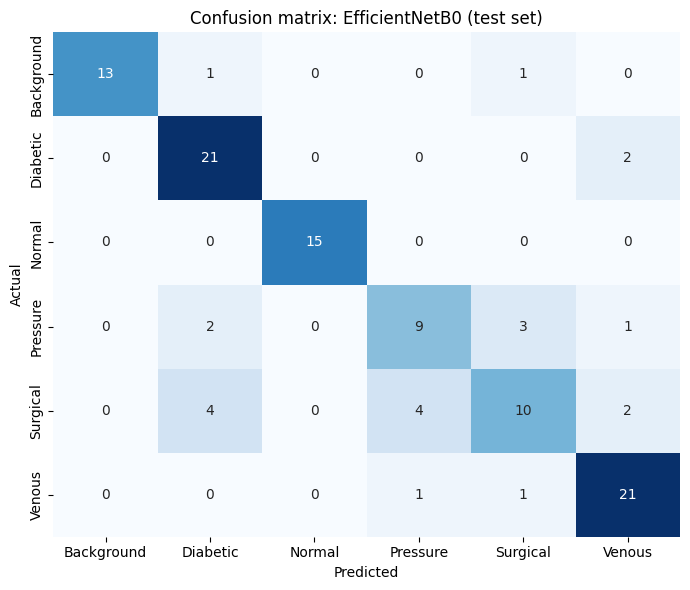

In [14]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

FIG_DIR = "/content/drive/MyDrive/WoundNet/figures"
os.makedirs(FIG_DIR, exist_ok=True)
COLORS = {"MLP": "#2a78d6", "CNN": "#eb6834", "MobileNetV2": "#1baf7a", "EfficientNetB0": "#eda100"}

df = pd.DataFrame(results)
df["family"] = df["model"].str.split("_").str[0]
df.to_csv(f"{FIG_DIR}/results_table.csv", index=False)

# 1. Model comparison
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(df["model"], df["macro_f1"], color=df["family"].map(COLORS), height=0.6)
for i, v in enumerate(df["macro_f1"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9, color="#333")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Test macro F1")
ax.set_title("Test macro F1 for every model and depth")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()]
ax.legend(handles, COLORS.keys(), loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/model_comparison.png", dpi=150)
plt.show()

# 2. Validation accuracy per epoch, best of each family
best_runs = ["MLP_1hidden", "CNN_4blocks", "MobileNetV2_0hidden", "EfficientNetB0_0hidden"]
fig, ax = plt.subplots(figsize=(9, 5))
for run in best_runs:
    va = histories[run]["val_accuracy"]
    ax.plot(range(1, len(va) + 1), va, color=COLORS[run.split("_")[0]], linewidth=2, label=run)
for e in (10, 20, 30):
    ax.axvline(e, color="#999", linestyle=":", linewidth=1)
ax.set_ylim(0, 1)
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy")
ax.set_title("Validation accuracy per epoch (best version of each model)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/training_curves.png", dpi=150)
plt.show()

# 3. Confusion matrix + per-class report for the winner (no TTA)
y_pred = best.predict(test_ds, verbose=0).argmax(axis=1)
print(classification_report(test_y, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(test_y, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix: EfficientNetB0 (test set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_matrix.png", dpi=150)
plt.show()

In [15]:
pd.DataFrame(results)

,model,params,val_acc_ep10,val_acc_ep20,val_acc_ep30,test_acc,macro_f1,train_time_s,ms_per_image
0,MLP_1hidden,6295046,0.360,0.387,0.378,0.378,0.288,19.1,1.95
1,MLP_2hidden,6424838,0.315,0.333,0.324,0.306,0.199,14.5,1.47
2,MLP_3hidden,6456966,0.306,0.243,0.216,0.207,0.057,15.9,1.63
3,CNN_2blocks,28870,0.468,0.604,0.640,0.514,0.493,58.8,2.40
4,CNN_3blocks,111430,0.468,0.622,0.613,0.577,0.579,65.7,2.97
5,CNN_4blocks,424006,0.577,0.550,0.550,0.541,0.535,71.4,3.62
6,MobileNetV2_0hidden,2265670,0.784,0.802,0.793,0.703,0.694,42.4,19.81
7,MobileNetV2_1hidden,2422726,0.775,0.802,0.775,0.703,0.708,42.3,20.36
8,MobileNetV2_2hidden,2619590,0.784,0.802,0.784,0.748,0.752,42.7,19.80
9,MobileNetV2_finetuned,2265670,0.793,0.793,0.793,0.748,0.748,16.4,20.03
